# 04.1 SVM (experimento 1)

- Entrada: `data/processed/dev_features.csv` (salida del notebook 03)
- Salida: resultados de validación cruzada de este modelo, para compararlos con los demás

Instrucciones:

- Validación: `GroupKFold(n_splits=5, shuffle=True, random_state=SEED)` agrupando por `animal_id_intake`. Es la misma en todos los notebooks.
- Hiperparámetros: salen de la búsqueda con Optuna del mismo modelo (carpeta `04-hyperparameter-optimization-experiment-1`), con `load_best(...)` y los nombres `svm_clf` y `svm_reg`. Si las variables o los datos cambian, hay que repetir esa búsqueda.
- Preprocesamiento: `build_preprocessor(columns=...)` dentro de un `Pipeline`, para que se ajuste en cada fold.
- Métricas: clasificación con macro-F1 y reporte por clase. Regresión con MAE en días (`np.expm1`) y R² en log.
- No usar `test`.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline

from config import SEED
from features import CAT_LOW, CAT_HIGH, BINARY, NUMERIC, FEATURES, build_preprocessor
from tuning import load_best

data = pd.read_csv("../../data/processed/dev_features.csv")
groups = data["animal_id_intake"]
cv = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)

/Users/klorenzoe/Documents/Personal/MUCSI/ML/mucsi-ml-animal-shelter-project/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Inputs

- `AVAILABLE`: las 22 variables de `dev_features.csv`.
- `FEATURES_EXP1_CLF` y `FEATURES_EXP1_REG`: variables del experimento 1 para este modelo, en clasificación y en regresión. Sin raza, color ni ciudad: menos columnas, entrenamiento más rápido.

In [2]:
AVAILABLE = FEATURES
FEATURES_EXP1_CLF = CAT_LOW + BINARY + NUMERIC
FEATURES_EXP1_REG = CAT_LOW + BINARY + NUMERIC

print("El experimento 1 usa estas variables:")
print("Clasificación:", FEATURES_EXP1_CLF)
print("Regresión:", FEATURES_EXP1_REG)

# Clasificación: todas las filas
y_clf = data["y_outcome"]

# Regresión: solo adoptados
adopted = data["y_outcome"] == "Adoption"
y_reg = data.loc[adopted, "y_log_days"]
groups_reg = groups[adopted]

El experimento 1 usa estas variables:
Clasificación: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']
Regresión: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']


In [3]:
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_predict
from sklearn.svm import SVC, SVR

## Hiperparámetros

Salen de la búsqueda con Optuna del experimento 1. Si las variables o los datos cambiaron desde esa búsqueda, `load_best` se detiene y avisa que hay que repetirla.

In [4]:
params_clf = load_best("svm_clf", FEATURES_EXP1_CLF)
params_reg = load_best("svm_reg", FEATURES_EXP1_REG)

Ajustes cargados de svm_clf.json: {'C': 4.016489512096986, 'gamma': 0.1189394949467549, 'class_weight': 'balanced'}
(en la búsqueda: macro-F1 = 0.4902)
Ajustes cargados de svm_reg.json: {'C': 0.6909036395860189, 'gamma': 0.37385999292747557, 'epsilon': 0.2922452532536278}
(en la búsqueda: R² (en log) = 0.2135)


## 1. Clasificación

Se evalúa con todos los datos. Cada fila se predice con un modelo que no la vio. Tarda unos 15 minutos.

macro-F1: 0.501  (siempre la clase más frecuente: 0.119)

                 precision    recall  f1-score   support

       Adoption       0.64      0.62      0.63     27073
     Euthanasia       0.57      0.65      0.61      4986
          Other       0.08      0.25      0.12       834
Return to Owner       0.56      0.72      0.63     11757
       Transfer       0.63      0.45      0.52     19031

       accuracy                           0.59     63681
      macro avg       0.49      0.54      0.50     63681
   weighted avg       0.61      0.59      0.59     63681



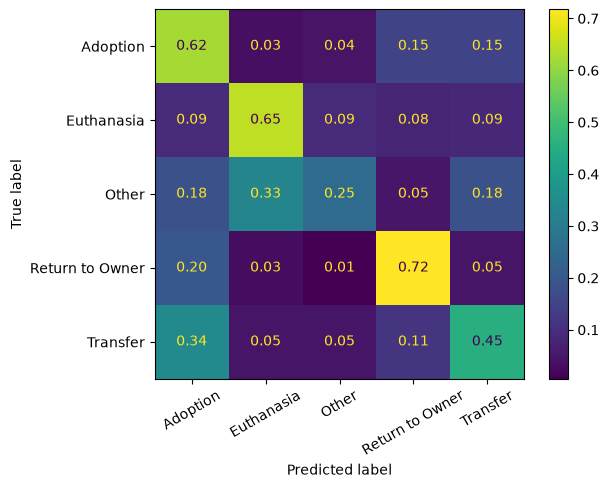

In [5]:
pipe_clf = Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP1_CLF)), ("model", SVC(**params_clf))])
X_clf = data[FEATURES_EXP1_CLF]

pred_clf = cross_val_predict(pipe_clf, X_clf, y_clf, groups=groups, cv=cv, n_jobs=5)
base_clf = cross_val_predict(DummyClassifier(strategy="most_frequent"), X_clf, y_clf, groups=groups, cv=cv)

print(f"macro-F1: {f1_score(y_clf, pred_clf, average='macro'):.3f}  (siempre la clase más frecuente: {f1_score(y_clf, base_clf, average='macro'):.3f})\n")
print(classification_report(y_clf, pred_clf))

ConfusionMatrixDisplay.from_predictions(y_clf, pred_clf, normalize="true", xticks_rotation=30, values_format=".2f")
plt.show()

## 2. Regresión

El error se reporta en días (`np.expm1`) y el R² en log.

In [6]:
pipe_reg = Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP1_REG)), ("model", SVR(**params_reg))])
X_reg = data.loc[adopted, FEATURES_EXP1_REG]

pred_log = cross_val_predict(pipe_reg, X_reg, y_reg, groups=groups_reg, cv=cv, n_jobs=5)
base_log = cross_val_predict(DummyRegressor(strategy="median"), X_reg, y_reg, groups=groups_reg, cv=cv)

days_real = np.expm1(y_reg)
pd.DataFrame({
    "R² (log)": [r2_score(y_reg, pred_log), r2_score(y_reg, base_log)],
    "MAE (días)": [mean_absolute_error(days_real, np.expm1(pred_log)), mean_absolute_error(days_real, np.expm1(base_log))],
}, index=["SVR", "Siempre la mediana"]).round(3)

,R² (log),MAE (días)
SVR,0.214,21.373
Siempre la mediana,-0.058,24.312


## 3. Resultados

In [7]:
pd.DataFrame({
    "Clasificación (macro-F1)": [round(f1_score(y_clf, pred_clf, average="macro"), 3)],
    "Regresión (R² log)": [round(r2_score(y_reg, pred_log), 3)],
    "Regresión (MAE días)": [round(mean_absolute_error(days_real, np.expm1(pred_log)), 3)],
}, index=["SVM"])

,Clasificación (macro-F1),Regresión (R² log),Regresión (MAE días)
SVM,0.501,0.214,21.373
